In [10]:
# Import the libraries required for data handling, numerical operations, and plotting.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [11]:
# Find the uploaded CSV dataset file in the current notebook environment.
import pandas as pd
import glob

files = glob.glob("/content/*.csv")

print(files)

['/content/healthcare_disease_prediction_2000.csv']


In [12]:
# Load the selected CSV dataset into a Pandas DataFrame named data.
file_path = files[0]

data = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Shape:", data.shape)

Dataset loaded successfully
Shape: (2000, 15)


In [13]:
# Display the first five rows to preview the dataset.
data.head()

,Patient_ID,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
0,1,69,Male,34.1,127,71,184,154,1,1,0,0,0,1,0
1,2,32,Male,25.0,148,69,177,136,1,1,1,0,0,0,0
2,3,78,Male,25.2,98,93,252,110,0,0,0,0,0,0,0
3,4,38,Male,9.6,162,102,274,87,1,0,1,0,0,0,0
4,5,41,Female,29.0,161,69,251,127,0,1,1,0,0,0,0


In [15]:
# Check the dataset columns and inspect example values from selected lifestyle features.
print(data.columns.tolist())

print(data[['Smoking', 'Alcohol_Intake',
            'Physical_Activity', 'Family_History']].head(10))

['Patient_ID', 'Age', 'Gender', 'BMI', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Cholesterol', 'Glucose_Level', 'Smoking', 'Alcohol_Intake', 'Physical_Activity', 'Family_History', 'Heart_Disease', 'Diabetes', 'Stroke']
   Smoking  Alcohol_Intake  Physical_Activity  Family_History
0        1               1                  0               0
1        1               1                  1               0
2        0               0                  0               0
3        1               0                  1               0
4        0               1                  1               0
5        1               1                  1               0
6        1               1                  1               0
7        1               0                  0               1
8        1               1                  1               0
9        1               0                  1               1


In [16]:
# Display column names, data types, and non-missing value counts.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                2000 non-null   int64  
 1   Age                       2000 non-null   int64  
 2   Gender                    2000 non-null   object 
 3   BMI                       2000 non-null   float64
 4   Blood_Pressure_Systolic   2000 non-null   int64  
 5   Blood_Pressure_Diastolic  2000 non-null   int64  
 6   Cholesterol               2000 non-null   int64  
 7   Glucose_Level             2000 non-null   int64  
 8   Smoking                   2000 non-null   int64  
 9   Alcohol_Intake            2000 non-null   int64  
 10  Physical_Activity         2000 non-null   int64  
 11  Family_History            2000 non-null   int64  
 12  Heart_Disease             2000 non-null   int64  
 13  Diabetes                  2000 non-null   int64  
 14  Stroke  

In [17]:
# Count missing values in each column.
data.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
BMI,0
Blood_Pressure_Systolic,0
Blood_Pressure_Diastolic,0
Cholesterol,0
Glucose_Level,0
Smoking,0
Alcohol_Intake,0


In [18]:
# Count duplicate rows in the dataset.
data.duplicated().sum()

np.int64(0)

In [19]:
# Convert categorical text values into numeric labels so the models can process them.
from sklearn.preprocessing import LabelEncoder

data_encoded = data.copy()

categorical_columns = [
    'Gender',
    'Smoking',
    'Alcohol_Intake',
    'Physical_Activity',
    'Family_History'
]

encoder = LabelEncoder()

for column in categorical_columns:
    data_encoded[column] = encoder.fit_transform(data_encoded[column])

data_encoded.head()

,Patient_ID,Age,Gender,BMI,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol,Glucose_Level,Smoking,Alcohol_Intake,Physical_Activity,Family_History,Heart_Disease,Diabetes,Stroke
0,1,69,1,34.1,127,71,184,154,1,1,0,0,0,1,0
1,2,32,1,25.0,148,69,177,136,1,1,1,0,0,0,0
2,3,78,1,25.2,98,93,252,110,0,0,0,0,0,0,0
3,4,38,1,9.6,162,102,274,87,1,0,1,0,0,0,0
4,5,41,0,29.0,161,69,251,127,0,1,1,0,0,0,0


In [20]:
# Separate input features (X) from the three disease target columns.
X = data_encoded.drop(
    ['Patient_ID', 'Heart_Disease', 'Diabetes', 'Stroke'],
    axis=1
)

y_heart = data_encoded['Heart_Disease']
y_diabetes = data_encoded['Diabetes']
y_stroke = data_encoded['Stroke']

print("Input features:")
print(X.columns)

print("\nNumber of input features:", X.shape[1])

Input features:
Index(['Age', 'Gender', 'BMI', 'Blood_Pressure_Systolic',
       'Blood_Pressure_Diastolic', 'Cholesterol', 'Glucose_Level', 'Smoking',
       'Alcohol_Intake', 'Physical_Activity', 'Family_History'],
      dtype='object')

Number of input features: 11


In [21]:
# Split the heart-disease data into training and testing sets.
from sklearn.model_selection import train_test_split

X_train_heart, X_test_heart, y_train_heart, y_test_heart = train_test_split(
    X,
    y_heart,
    test_size=0.2,
    random_state=42,
    stratify=y_heart
)

print("Training data:", X_train_heart.shape)
print("Testing data:", X_test_heart.shape)

Training data: (1600, 11)
Testing data: (400, 11)


In [22]:
# Create and train a Random Forest classifier for heart-disease prediction.
from sklearn.ensemble import RandomForestClassifier

rf_heart = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_heart.fit(X_train_heart, y_train_heart)

print("Random Forest trained successfully")

Random Forest trained successfully


In [23]:
# Create and train an SVM classifier for heart-disease prediction.
from sklearn.svm import SVC

svm_heart = SVC(
    probability=True,
    random_state=42
)

svm_heart.fit(X_train_heart, y_train_heart)

print("SVM trained successfully")

SVM trained successfully


In [24]:
# Create and train a Logistic Regression classifier for heart-disease prediction.
from sklearn.linear_model import LogisticRegression

lr_heart = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_heart.fit(X_train_heart, y_train_heart)

print("Logistic Regression trained successfully")

Logistic Regression trained successfully


In [25]:
# Combine the three heart-disease classifiers using a soft-voting ensemble and train it.
from sklearn.ensemble import VotingClassifier

ensemble_heart = VotingClassifier(
    estimators=[
        ('random_forest', rf_heart),
        ('svm', svm_heart),
        ('logistic_regression', lr_heart)
    ],
    voting='soft'
)

ensemble_heart.fit(X_train_heart, y_train_heart)

print("Ensemble model trained successfully")

Ensemble model trained successfully


In [26]:
# Generate heart-disease predictions on the test data using each individual model and the
rf_pred = rf_heart.predict(X_test_heart)
svm_pred = svm_heart.predict(X_test_heart)
lr_pred = lr_heart.predict(X_test_heart)
ensemble_pred = ensemble_heart.predict(X_test_heart)

print("Predictions completed successfully")

Predictions completed successfully


In [27]:
# Calculate and compare the test accuracy of the heart-disease models.
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test_heart, rf_pred)
svm_accuracy = accuracy_score(y_test_heart, svm_pred)
lr_accuracy = accuracy_score(y_test_heart, lr_pred)
ensemble_accuracy = accuracy_score(y_test_heart, ensemble_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("SVM Accuracy:", svm_accuracy)
print("Logistic Regression Accuracy:", lr_accuracy)
print("Ensemble Accuracy:", ensemble_accuracy)

Random Forest Accuracy: 0.99
SVM Accuracy: 0.9475
Logistic Regression Accuracy: 0.95
Ensemble Accuracy: 0.98


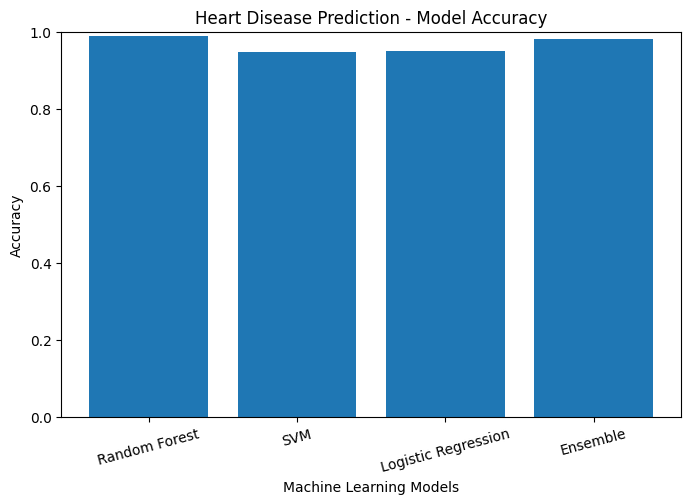

In [28]:
# Prepare the model names and accuracy values for a heart-disease comparison chart.
models = [
    'Random Forest',
    'SVM',
    'Logistic Regression',
    'Ensemble'
]

accuracies = [
    rf_accuracy,
    svm_accuracy,
    lr_accuracy,
    ensemble_accuracy
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.title("Heart Disease Prediction - Model Accuracy")
plt.xticks(rotation=15)
plt.show()

In [29]:
# Print precision, recall, F1-score, and other classification metrics for the heart ensemble.
from sklearn.metrics import classification_report

print("Ensemble Model Classification Report:")
print(classification_report(y_test_heart, ensemble_pred))

Ensemble Model Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       368
           1       1.00      0.75      0.86        32

    accuracy                           0.98       400
   macro avg       0.99      0.88      0.92       400
weighted avg       0.98      0.98      0.98       400



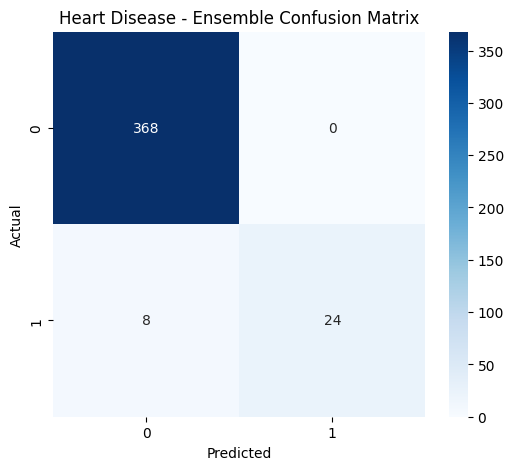

In [30]:
# Create and display a confusion matrix for the heart-disease ensemble predictions.
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_heart, ensemble_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heart Disease - Ensemble Confusion Matrix")
plt.show()

In [31]:
# Split the diabetes data into training and testing sets.
X_train_diabetes, X_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    X,
    y_diabetes,
    test_size=0.2,
    random_state=42,
    stratify=y_diabetes
)

print("Training data:", X_train_diabetes.shape)
print("Testing data:", X_test_diabetes.shape)

Training data: (1600, 11)
Testing data: (400, 11)


In [32]:
# Create and train a Random Forest classifier for diabetes prediction.
rf_diabetes = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_diabetes.fit(X_train_diabetes, y_train_diabetes)

print("Diabetes Random Forest trained successfully")

Diabetes Random Forest trained successfully


In [33]:
# Create and train an SVM classifier for diabetes prediction.
svm_diabetes = SVC(
    probability=True,
    random_state=42
)

svm_diabetes.fit(X_train_diabetes, y_train_diabetes)

print("Diabetes SVM trained successfully")

Diabetes SVM trained successfully


In [34]:
# Create and train a Logistic Regression classifier for diabetes prediction.
lr_diabetes = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_diabetes.fit(X_train_diabetes, y_train_diabetes)

print("Diabetes Logistic Regression trained successfully")

Diabetes Logistic Regression trained successfully


In [35]:
# Combine the three diabetes classifiers using a soft-voting ensemble and train it.
ensemble_diabetes = VotingClassifier(
    estimators=[
        ('random_forest', rf_diabetes),
        ('svm', svm_diabetes),
        ('logistic_regression', lr_diabetes)
    ],
    voting='soft'
)

ensemble_diabetes.fit(
    X_train_diabetes,
    y_train_diabetes
)

print("Diabetes Ensemble trained successfully")

Diabetes Ensemble trained successfully


In [36]:
# Generate diabetes predictions on the test data using each individual model and the ensemble.
rf_diabetes_pred = rf_diabetes.predict(X_test_diabetes)
svm_diabetes_pred = svm_diabetes.predict(X_test_diabetes)
lr_diabetes_pred = lr_diabetes.predict(X_test_diabetes)
ensemble_diabetes_pred = ensemble_diabetes.predict(X_test_diabetes)

print("Diabetes predictions completed")

Diabetes predictions completed


In [37]:
# Calculate and compare the test accuracy of the diabetes models.
rf_diabetes_accuracy = accuracy_score(
    y_test_diabetes,
    rf_diabetes_pred
)

svm_diabetes_accuracy = accuracy_score(
    y_test_diabetes,
    svm_diabetes_pred
)

lr_diabetes_accuracy = accuracy_score(
    y_test_diabetes,
    lr_diabetes_pred
)

ensemble_diabetes_accuracy = accuracy_score(
    y_test_diabetes,
    ensemble_diabetes_pred
)

print("Random Forest Accuracy:", rf_diabetes_accuracy)
print("SVM Accuracy:", svm_diabetes_accuracy)
print("Logistic Regression Accuracy:", lr_diabetes_accuracy)
print("Ensemble Accuracy:", ensemble_diabetes_accuracy)

Random Forest Accuracy: 0.995
SVM Accuracy: 0.87
Logistic Regression Accuracy: 0.93
Ensemble Accuracy: 0.97


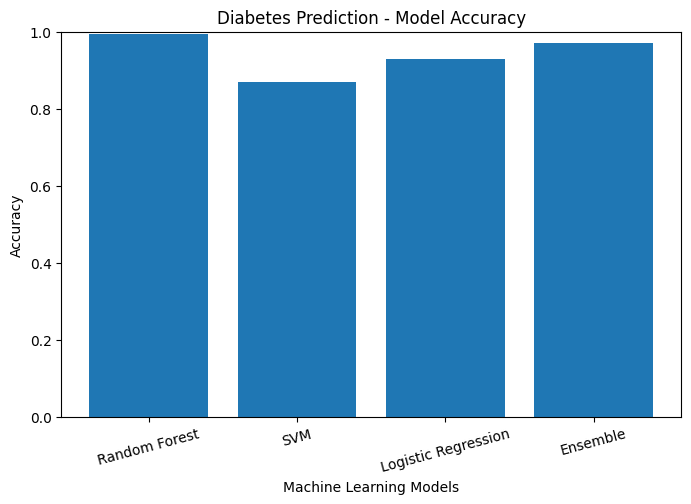

In [38]:
# Prepare the diabetes model names and accuracy values for a comparison chart
models = [
    'Random Forest',
    'SVM',
    'Logistic Regression',
    'Ensemble'
]

accuracies = [
    rf_diabetes_accuracy,
    svm_diabetes_accuracy,
    lr_diabetes_accuracy,
    ensemble_diabetes_accuracy
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.title("Diabetes Prediction - Model Accuracy")
plt.xticks(rotation=15)
plt.show()

In [39]:
# Print the classification metrics for the diabetes ensemble.
print("Diabetes Ensemble Classification Report:")
print(
    classification_report(
        y_test_diabetes,
        ensemble_diabetes_pred
    )
)

Diabetes Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       348
           1       0.90      0.87      0.88        52

    accuracy                           0.97       400
   macro avg       0.94      0.93      0.93       400
weighted avg       0.97      0.97      0.97       400



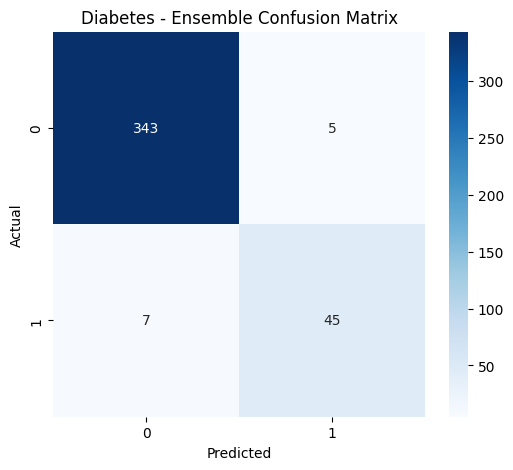

In [40]:
# Create and display a confusion matrix for the diabetes ensemble predictions.
cm = confusion_matrix(
    y_test_diabetes,
    ensemble_diabetes_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Diabetes - Ensemble Confusion Matrix")

plt.show()

In [41]:
# Split the stroke data into training and testing sets.
X_train_stroke, X_test_stroke, y_train_stroke, y_test_stroke = train_test_split(
    X,
    y_stroke,
    test_size=0.2,
    random_state=42,
    stratify=y_stroke
)

print("Training data:", X_train_stroke.shape)
print("Testing data:", X_test_stroke.shape)

Training data: (1600, 11)
Testing data: (400, 11)


In [42]:
# Create and train a Random Forest classifier for stroke prediction.
rf_stroke = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_stroke.fit(X_train_stroke, y_train_stroke)

print("Stroke Random Forest trained successfully")

Stroke Random Forest trained successfully


In [43]:
# Create and train an SVM classifier for stroke prediction.
svm_stroke = SVC(
    probability=True,
    random_state=42
)

svm_stroke.fit(X_train_stroke, y_train_stroke)

print("Stroke SVM trained successfully")

Stroke SVM trained successfully


In [44]:
# Create and train a Logistic Regression classifier for stroke prediction.
lr_stroke = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_stroke.fit(X_train_stroke, y_train_stroke)

print("Stroke Logistic Regression trained successfully")

Stroke Logistic Regression trained successfully


In [45]:
# Combine the three stroke classifiers using a soft-voting ensemble and train it.
ensemble_stroke = VotingClassifier(
    estimators=[
        ('random_forest', rf_stroke),
        ('svm', svm_stroke),
        ('logistic_regression', lr_stroke)
    ],
    voting='soft'
)

ensemble_stroke.fit(
    X_train_stroke,
    y_train_stroke
)

print("Stroke Ensemble trained successfully")

Stroke Ensemble trained successfully


In [46]:
# Generate stroke predictions on the test data using each individual model and the ensemble.
rf_stroke_pred = rf_stroke.predict(X_test_stroke)
svm_stroke_pred = svm_stroke.predict(X_test_stroke)
lr_stroke_pred = lr_stroke.predict(X_test_stroke)
ensemble_stroke_pred = ensemble_stroke.predict(X_test_stroke)

print("Stroke predictions completed")

Stroke predictions completed


In [47]:
# Calculate and compare the test accuracy of the stroke models.
rf_stroke_accuracy = accuracy_score(
    y_test_stroke,
    rf_stroke_pred
)

svm_stroke_accuracy = accuracy_score(
    y_test_stroke,
    svm_stroke_pred
)

lr_stroke_accuracy = accuracy_score(
    y_test_stroke,
    lr_stroke_pred
)

ensemble_stroke_accuracy = accuracy_score(
    y_test_stroke,
    ensemble_stroke_pred
)

print("Random Forest Accuracy:", rf_stroke_accuracy)
print("SVM Accuracy:", svm_stroke_accuracy)
print("Logistic Regression Accuracy:", lr_stroke_accuracy)
print("Ensemble Accuracy:", ensemble_stroke_accuracy)

Random Forest Accuracy: 1.0
SVM Accuracy: 0.95
Logistic Regression Accuracy: 0.985
Ensemble Accuracy: 0.985


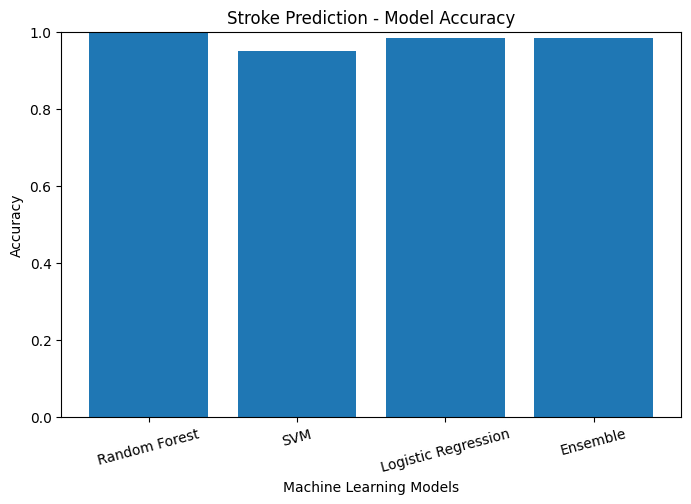

In [48]:
# Prepare the stroke model names and accuracy values for a comparison chart
models = [
    'Random Forest',
    'SVM',
    'Logistic Regression',
    'Ensemble'
]

accuracies = [
    rf_stroke_accuracy,
    svm_stroke_accuracy,
    lr_stroke_accuracy,
    ensemble_stroke_accuracy
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.title("Stroke Prediction - Model Accuracy")
plt.xticks(rotation=15)
plt.show()

In [49]:
# Print the classification metrics for the stroke ensemble.
print("Stroke Ensemble Classification Report:")

print(
    classification_report(
        y_test_stroke,
        ensemble_stroke_pred
    )
)

Stroke Ensemble Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       380
           1       1.00      0.70      0.82        20

    accuracy                           0.98       400
   macro avg       0.99      0.85      0.91       400
weighted avg       0.99      0.98      0.98       400



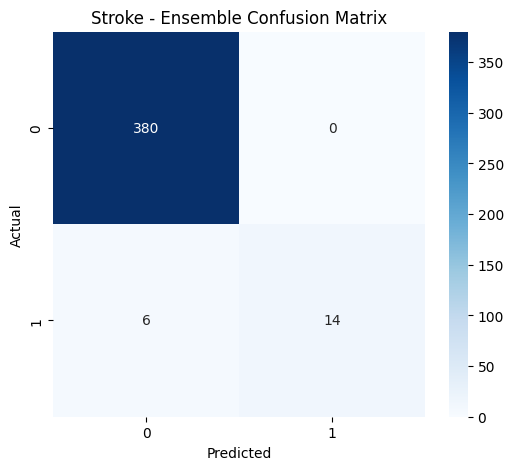

In [50]:
# Create and display a confusion matrix for the stroke ensemble predictions.
cm = confusion_matrix(
    y_test_stroke,
    ensemble_stroke_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Stroke - Ensemble Confusion Matrix")

plt.show()

In [51]:
# Create a folder to store the trained machine-learning model files.
import os

os.makedirs("model", exist_ok=True)

print("Model folder created")

Model folder created


In [52]:
# Save the trained heart-disease ensemble model to a file.
import joblib

joblib.dump(ensemble_heart, "model/heart_disease_model.pkl")

print("Heart Disease model saved")

Heart Disease model saved


In [53]:
# Save the trained diabetes ensemble model to a file.
joblib.dump(ensemble_diabetes, "model/diabetes_model.pkl")

print("Diabetes model saved")

Diabetes model saved


In [54]:
# Save the trained stroke ensemble model to a file.
joblib.dump(ensemble_stroke, "model/stroke_model.pkl")

print("Stroke model saved")

Stroke model saved


In [55]:
# Save the input feature-column names so the application can use the same feature order.
feature_columns = list(X.columns)

joblib.dump(
    feature_columns,
    "model/feature_columns.pkl"
)

print("Feature columns saved:")
print(feature_columns)

Feature columns saved:
['Age', 'Gender', 'BMI', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Cholesterol', 'Glucose_Level', 'Smoking', 'Alcohol_Intake', 'Physical_Activity', 'Family_History']


In [56]:
# Print the overall test accuracy of each disease ensemble model.
from sklearn.metrics import accuracy_score

# Heart Disease Accuracy
heart_pred = ensemble_heart.predict(X_test_heart)
heart_accuracy = accuracy_score(y_test_heart, heart_pred)

# Diabetes Accuracy
diabetes_pred = ensemble_diabetes.predict(X_test_diabetes)
diabetes_accuracy = accuracy_score(y_test_diabetes, diabetes_pred)

# Stroke Accuracy
stroke_pred = ensemble_stroke.predict(X_test_stroke)
stroke_accuracy = accuracy_score(y_test_stroke, stroke_pred)

print("Model Ensemble Accuracy Results")
print("--------------------------------")
print(f"Heart Disease Accuracy : {heart_accuracy * 100:.2f}%")
print(f"Diabetes Accuracy      : {diabetes_accuracy * 100:.2f}%")
print(f"Stroke Accuracy        : {stroke_accuracy * 100:.2f}%")

Model Ensemble Accuracy Results
--------------------------------
Heart Disease Accuracy : 98.00%
Diabetes Accuracy      : 97.00%
Stroke Accuracy        : 98.50%


In [57]:
# Compare the accuracy of Random Forest, SVM, Logistic Regression, and the voting ensemble.
from sklearn.metrics import accuracy_score

models = {
    "Random Forest": "random_forest",
    "SVM": "svm",
    "Logistic Regression": "logistic_regression"
}

print("HEART DISEASE MODEL ACCURACIES")
print("--------------------------------")

for name, model_name in models.items():
    model = ensemble_heart.named_estimators_[model_name]
    prediction = model.predict(X_test_heart)
    accuracy = accuracy_score(y_test_heart, prediction)
    print(f"{name}: {accuracy * 100:.2f}%")

print("\nDIABETES MODEL ACCURACIES")
print("--------------------------------")

for name, model_name in models.items():
    model = ensemble_diabetes.named_estimators_[model_name]
    prediction = model.predict(X_test_diabetes)
    accuracy = accuracy_score(y_test_diabetes, prediction)
    print(f"{name}: {accuracy * 100:.2f}%")

print("\nSTROKE MODEL ACCURACIES")
print("--------------------------------")

for name, model_name in models.items():
    model = ensemble_stroke.named_estimators_[model_name]
    prediction = model.predict(X_test_stroke)
    accuracy = accuracy_score(y_test_stroke, prediction)
    print(f"{name}: {accuracy * 100:.2f}%")

HEART DISEASE MODEL ACCURACIES
--------------------------------
Random Forest: 99.00%
SVM: 94.75%
Logistic Regression: 95.00%

DIABETES MODEL ACCURACIES
--------------------------------
Random Forest: 99.50%
SVM: 87.00%
Logistic Regression: 93.00%

STROKE MODEL ACCURACIES
--------------------------------
Random Forest: 100.00%
SVM: 95.00%
Logistic Regression: 98.50%


HEART DISEASE - CLASSIFICATION REPORT
--------------------------------------
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       368
           1       1.00      0.75      0.86        32

    accuracy                           0.98       400
   macro avg       0.99      0.88      0.92       400
weighted avg       0.98      0.98      0.98       400



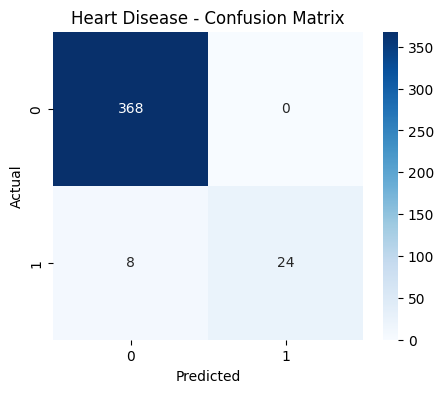

DIABETES - CLASSIFICATION REPORT
--------------------------------
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       348
           1       0.90      0.87      0.88        52

    accuracy                           0.97       400
   macro avg       0.94      0.93      0.93       400
weighted avg       0.97      0.97      0.97       400



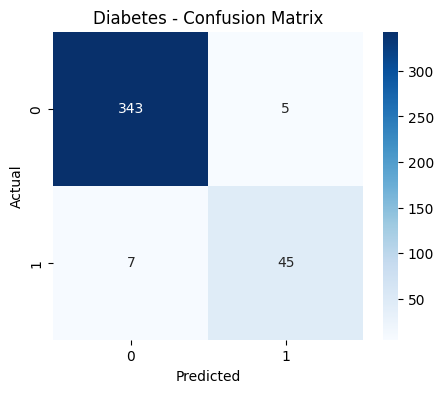

STROKE - CLASSIFICATION REPORT
------------------------------
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       380
           1       1.00      0.70      0.82        20

    accuracy                           0.98       400
   macro avg       0.99      0.85      0.91       400
weighted avg       0.99      0.98      0.98       400



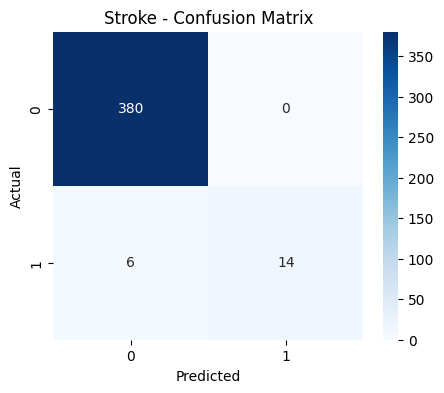

In [92]:
# Display detailed classification reports and confusion matrices for all three diseases.
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------- HEART DISEASE ----------------
heart_pred = ensemble_heart.predict(X_test_heart)

print("HEART DISEASE - CLASSIFICATION REPORT")
print("--------------------------------------")
print(classification_report(y_test_heart, heart_pred))

cm_heart = confusion_matrix(y_test_heart, heart_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_heart, annot=True, fmt='d', cmap='Blues')
plt.title("Heart Disease - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ---------------- DIABETES ----------------
diabetes_pred = ensemble_diabetes.predict(X_test_diabetes)

print("DIABETES - CLASSIFICATION REPORT")
print("--------------------------------")
print(classification_report(y_test_diabetes, diabetes_pred))

cm_diabetes = confusion_matrix(y_test_diabetes, diabetes_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_diabetes, annot=True, fmt='d', cmap='Blues')
plt.title("Diabetes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ---------------- STROKE ----------------
stroke_pred = ensemble_stroke.predict(X_test_stroke)

print("STROKE - CLASSIFICATION REPORT")
print("------------------------------")
print(classification_report(y_test_stroke, stroke_pred))

cm_stroke = confusion_matrix(y_test_stroke, stroke_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm_stroke, annot=True, fmt='d', cmap='Blues')
plt.title("Stroke - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [58]:
# Compare average disease-label values across physical-activity groups for a simple extra
print(data[["Physical_Activity", "Heart_Disease", "Diabetes", "Stroke"]].groupby("Physical_Activity").mean())

                   Heart_Disease  Diabetes    Stroke
Physical_Activity                                   
0                       0.078218  0.128713  0.049505
1                       0.082828  0.133333  0.052525
